# 105 Confidence-aware metrics: is log power worse, or just less confident?

`s7-gpc-tukey-logpower-1k` paints its masks at lower confidence than the magnitude runs, so the training metric (**soft IoU** =
Σ min(p, y) / Σ max(p, y)) charges it for every pixel below 1, even where it has the right place. This notebook rescores the saved eval
masks of three runs at **epoch 500** (the logpower run crashed at ~ep750 and its ep750 outputs are partly truncated; ep500 is also its
only checkpoint) with metrics that do not punish calibration. The s6 run trains for 3000 epochs, so at ep500 its LR is still high: it
is not schedule-matched to the two 1000-epoch s7 runs.

| metric | what it asks | needs a threshold? |
|---|---|---|
| soft IoU | the training metric: right place **and** confident | no |
| IoU @ t | binarize at p > t, then IoU vs y > 0.5 | yes: t per run, chosen on **train** outputs, so eval never picks it |
| top-k IoU | binarize the k most confident pixels, k = true object area | no, but uses the true area (an oracle for size) |
| AP | pixel average precision per sample: does the model rank object pixels above background? | no |
| BCE / reliability | is p = 0.3 right 30% of the time? | no |

Only eval splits that all three runs have; samples with an empty true mask are left out of the IoU-type metrics (IoU is undefined there).

**Findings (ep500, 55 common eval splits)**
- **The ranking does not change with the metric.** tukey-base > s6 > logpower on soft IoU (.347 / .330 / .310), every hard-IoU threshold,
  top-k IoU (.391 / .378 / .359) and AP (.502 / .489 / .469). The soft IoU here matches the training logs, which is the sanity check.
- **Lowering the threshold helps every run a little and all about the same.** IoU is flat for t = 0.02-0.1 and falls above that. logpower
  gains the most (+.017 at t = .02 vs soft IoU) but stays last. t = 0.08: .355 / .341 / .324.
- **Overall, logpower is not less confident at ep500.** All three are almost binary (p ≈ 0 or ≈ 1) with near-identical reliability curves and
  ECE (~.009). Its lower mean p inside the object (.42 vs .49) comes from *missing* object pixels outright, which AP and top-k IoU count too.
- **Where logpower actually loses is plastic** (id AP .84 vs .91, ood .42 vs .49). On cardboard it beats s6 on every metric; on gastro ood the three are tied.
- Picking the threshold on train outputs gives t* = 0.5 for every run: train masks are confident, so train is the wrong place to tune a
  threshold. A held-out validation split would be needed for a fair per-run threshold.


In [1]:
import os, sys, re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import average_precision_score

RUNS = os.environ.get("RUNS", "s7-gpc-tukey-base-1k,s6-gastro-plastic-cardboard-3k,s7-gpc-tukey-logpower-1k").split(",")
EPOCH = int(os.environ.get("EPOCH", 500))
T = np.array([0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7])  # thresholds to scan
OUT = 64

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO / "src7"))
from dataset import EXPERIMENTS, CATEGORIES, NOT_OOD, collect_samples

COLOR = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a"]))  # dataviz categorical slots 1-3
SHORT = {r: re.sub(r"^(s\d)-|-\d+k$", "", r) for r in RUNS}
CAT = {(box, split): cat for box, cats in CATEGORIES.items() for cat, splits in cats.items() for split in splits}

/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


## 1 Saved masks and true masks

In [2]:
def load_outputs(run, part):
    # {(split, (experiment, position_id, speaker)): mask (64,64) float32}; part = "eval" or "train"
    out = {}
    for f in sorted((REPO / f"runs/{run}/outputs_history/{part}").rglob(f"ep{EPOCH:04d}-*.pt")):
        try: d = torch.load(f, weights_only=False)
        except RuntimeError: print(f"skipped unreadable {f.relative_to(REPO)}"); continue  # the logpower run died mid-save
        split = "train" if part == "train" else "/".join(f.parent.relative_to(REPO / f"runs/{run}/outputs_history/eval").parts)
        for p, e, pos, spk in zip(d["mask_pred"], d["info"]["experiment"], d["info"]["position_id"].tolist(), d["info"]["speaker"].tolist()):
            out[split, (e, pos, spk)] = p.float().numpy()
    return out

EVAL = {r: load_outputs(r, "eval") for r in RUNS}
TRAIN = {r: load_outputs(r, "train") for r in RUNS}
common = set.intersection(*({s for s, _ in EVAL[r]} for r in RUNS))
print({SHORT[r]: (len(EVAL[r]), len(TRAIN[r])) for r in RUNS}, f"{len(common)} common eval splits")

# true masks: the 64x64 BOX resize of 03_smask.png, as src7 process_y; with-lid samples take the lid-free target at the same spot
exps = sorted({k[0] for r in RUNS for _, k in [*EVAL[r], *TRAIN[r]]})
SAMPLES = {(m["experiment"], m["position_id"], m["speaker"]): (d, m) for e in exps for d, m in collect_samples(EXPERIMENTS / e).items()}
def truth(key):
    d, m = SAMPLES[key]
    if "without_lid_position_id" in m: d, m = SAMPLES[m["experiment"], m["without_lid_position_id"], m["speaker"]]
    return np.clip(np.asarray(Image.open(d / "image/03_smask.png").convert("F").resize((OUT, OUT), Image.BOX), np.float32) / 255, 0, 1)
keys = {k for r in RUNS for _, k in [*EVAL[r], *TRAIN[r]]}
GT = {k: truth(k) for k in keys}
print(f"{len(GT)} true masks")

{'gpc-tukey-base': (4560, 11264), 'gastro-plastic-cardboard': (4796, 11264), 'gpc-tukey-logpower': (4560, 11264)} 55 common eval splits


collecting 2026_09_27_gastronorm_four_objs:   0%|          | 0/6155 [00:00<?, ?it/s]

collecting 2026_09_27_gastronorm_four_objs:  13%|█▎        | 771/6155 [00:00<00:00, 7708.87it/s]

collecting 2026_09_27_gastronorm_four_objs:  25%|██▌       | 1542/6155 [00:00<00:01, 2919.40it/s]

collecting 2026_09_27_gastronorm_four_objs:  32%|███▏      | 1980/6155 [00:00<00:02, 1975.61it/s]

...

collecting 2026_10_11_cardboard_four_objs:  82%|████████▏ | 5953/7228 [00:02<00:00, 3182.99it/s]

collecting 2026_10_11_cardboard_four_objs:  93%|█████████▎| 6718/7228 [00:02<00:00, 3884.94it/s]

collecting 2026_10_11_cardboard_four_objs: 100%|██████████| 7228/7228 [00:02<00:00, 2945.62it/s]

2026_10_11_cardboard_four_objs: 7228 samples, skipped 0 incomplete: []


16595 true masks


## 2 Per-sample metrics

In [3]:
def score(p, y):
    obj, k = y > 0.5, int(round(y.sum()))
    if not obj.any(): return None                                                            # empty box: IoU undefined
    hard = p[None] > T[:, None, None]                                                        # (T,H,W)
    top = p >= np.sort(p.ravel())[-k] if k else np.zeros_like(obj)
    return dict(soft_iou=np.minimum(p, y).sum() / np.maximum(p, y).sum(),
                **{f"iou@{t:g}": (h & obj).sum() / (h | obj).sum() for t, h in zip(T, hard)},
                topk_iou=(top & obj).sum() / (top | obj).sum(),
                ap=average_precision_score(obj.ravel(), p.ravel()),
                bce=-np.mean(y * np.log(p.clip(1e-6)) + (1 - y) * np.log((1 - p).clip(1e-6))),
                p_obj=p[obj].mean(), p_bg=p[~obj].mean())

rows = []
for r in RUNS:
    for (split, key), p in EVAL[r].items():
        if split not in common: continue
        s = score(p, GT[key])
        if s: rows.append(dict(run=SHORT[r], split=split, box=split.split("/")[0], cat=CAT.get(tuple(split.split("/")), "other"), **s))
    for (_, key), p in TRAIN[r].items():
        s = score(p, GT[key])
        if s: rows.append(dict(run=SHORT[r], split="train", box="train", cat="train", **s))
df = pd.DataFrame(rows)
ev, tr = df[df.split != "train"], df[df.split == "train"]
print(ev.groupby("run", sort=False).size().to_dict(), "eval samples;", tr.groupby("run", sort=False).size().to_dict(), "train samples")

{'gpc-tukey-base': 4382, 'gastro-plastic-cardboard': 4618, 'gpc-tukey-logpower': 4382} eval samples; {'gpc-tukey-base': 11103, 'gastro-plastic-cardboard': 11102, 'gpc-tukey-logpower': 11103} train samples


## 3 IoU vs threshold

Mean over the common eval splits (each split counts once, as in the training logs). The dot on each curve is the threshold that run would
pick from its **train** outputs at the same epoch: that is the fair "best threshold" number; the curve's own peak is chosen on eval and
slightly optimistic.

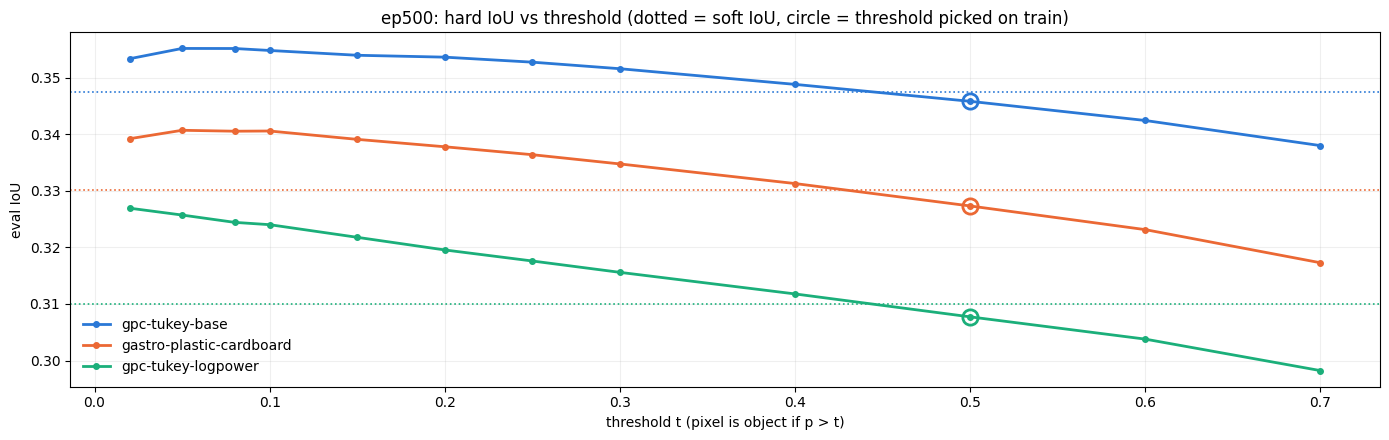

In [4]:
split_mean = lambda d, cols: d.groupby(["run", "split"], sort=False)[cols].mean().groupby("run", sort=False).mean()
iou_cols = [f"iou@{t:g}" for t in T]
curve, train_curve = split_mean(ev, iou_cols), tr.groupby("run", sort=False)[iou_cols].mean()
T_STAR = {run: T[np.argmax(train_curve.loc[run])] for run in curve.index}

fig, ax = plt.subplots(figsize=(14, 4.5))
for r in RUNS:
    run = SHORT[r]
    ax.plot(T, curve.loc[run], lw=2, marker="o", ms=4, color=COLOR[r], label=run)
    t = T_STAR[run]; ax.plot(t, curve.loc[run, f"iou@{t:g}"], "o", ms=11, mfc="none", mew=2, color=COLOR[r])
    ax.axhline(split_mean(ev, ["soft_iou"]).loc[run, "soft_iou"], color=COLOR[r], ls=":", lw=1.2)
ax.set_xlabel("threshold t (pixel is object if p > t)"); ax.set_ylabel("eval IoU"); ax.grid(alpha=0.2)
ax.set_title(f"ep{EPOCH}: hard IoU vs threshold (dotted = soft IoU, circle = threshold picked on train)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 4 Summary table

In [5]:
cols = ["soft_iou", "iou@0.5", "topk_iou", "ap", "bce", "p_obj", "p_bg"]
tab = split_mean(ev, cols)
tab.insert(2, "t*", pd.Series(T_STAR))
tab.insert(3, "iou@t*", pd.Series({run: curve.loc[run, f"iou@{t:g}"] for run, t in T_STAR.items()}))
tab.insert(4, "iou@0.08", curve["iou@0.08"])
tab.round(3)

,soft_iou,iou@0.5,t*,iou@t*,iou@0.08,topk_iou,ap,bce,p_obj,p_bg
run,,,,,,,,,,
gpc-tukey-base,0.347,0.346,0.5,0.346,0.355,0.391,0.502,0.097,0.487,0.005
gastro-plastic-cardboard,0.330,0.327,0.5,0.327,0.341,0.378,0.489,0.099,0.470,0.005
gpc-tukey-logpower,0.310,0.308,0.5,0.308,0.324,0.359,0.469,0.098,0.417,0.004


In [6]:
# the same, split into in-distribution (id + control) and out-of-distribution (every other category), per box
ev2 = ev.assign(group=np.where(ev.cat.isin(NOT_OOD), "id", "ood"))
ev2 = ev2.assign(**{"iou@t*": [r[f"iou@{T_STAR[r['run']]:g}"] for _, r in ev2.iterrows()]})
g = ev2.groupby(["box", "group", "run", "split"], sort=False)[["soft_iou", "iou@t*", "topk_iou", "ap"]].mean().groupby(["box", "group", "run"], sort=False).mean()
g.unstack("run").round(3)

soft_iou                                              \
run             gpc-tukey-base gastro-plastic-cardboard gpc-tukey-logpower   
box       group                                                              
cardboard ood            0.200                    0.177              0.182   
          id             0.494                    0.433              0.443   
gastro    ood            0.231                    0.230              0.231   
          id             0.545                    0.531              0.502   
plastic   ood            0.333                    0.334              0.274   
          id             0.730                    0.708              0.640   

                        iou@t*                                              \
run             gpc-tukey-base gastro-plastic-cardboard gpc-tukey-logpower   
box       group                                                              
cardboard ood            0.198                    0.174              0.181   
          id             0.494                    0.432              0.441   
gastro    ood            0.228                    0.223              0.226   
          id             0.546                    0.530              0.501   
plastic   ood            0.329                    0.331              0.269   
          id             0.730                    0.709              0.642   

                      topk_iou                                              \
run             gpc-tukey-base gastro-plastic-cardboard gpc-tukey-logpower   
box       group                                                              
cardboard ood            0.251                    0.232              0.245   
          id             0.539                    0.481              0.512   
gastro    ood            0.263                    0.268              0.265   
          id             0.573                    0.566              0.545   
plastic   ood            0.390                    0.395              0.315   
          id             0.747                    0.726              0.663   

                            ap                                              
run             gpc-tukey-base gastro-plastic-cardboard gpc-tukey-logpower  
box       group                                                             
cardboard ood            0.336                    0.313              0.328  
          id             0.691                    0.629              0.651  
gastro    ood            0.344                    0.357              0.356  
          id             0.734                    0.735              0.702  
plastic   ood            0.494                    0.499              0.418  
          id             0.912                    0.898              0.841

## 5 Calibration

Pooled over every eval pixel: predicted p (binned) vs the fraction of those pixels that are object. On the diagonal = calibrated; below =
overconfident; above = underconfident. Right: where each run's probabilities sit inside vs outside the object.

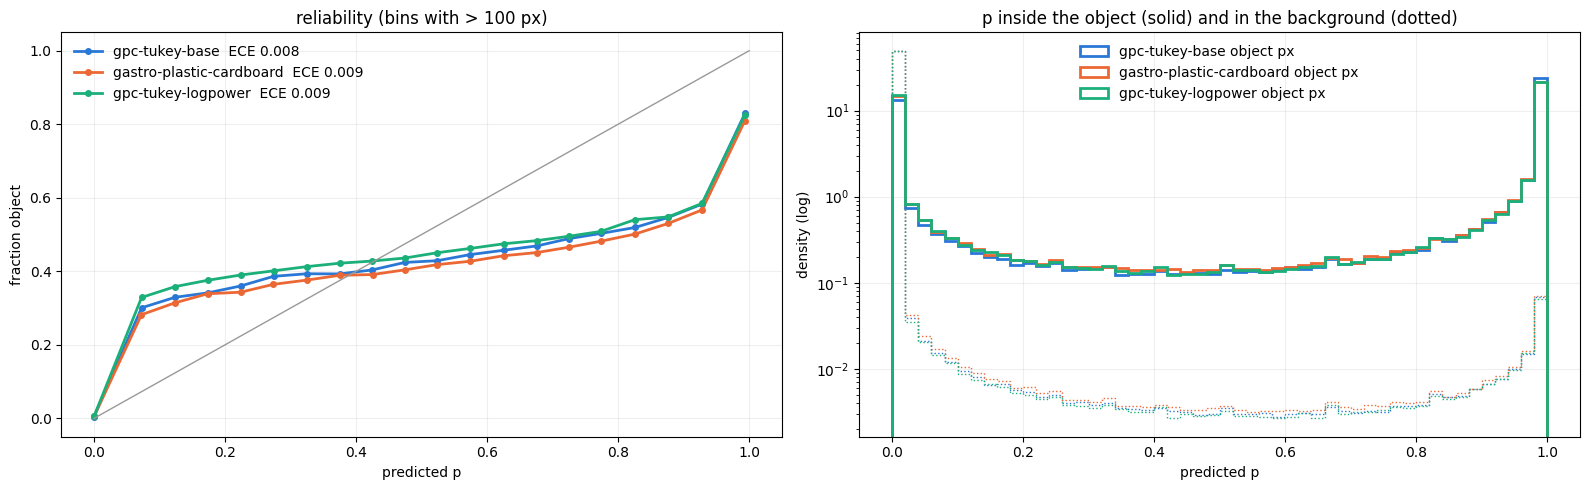

In [7]:
bins = np.linspace(0, 1, 21)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for r in RUNS:
    ps = [(p, GT[k]) for (s, k), p in EVAL[r].items() if s in common]
    P, Y = np.concatenate([p.ravel() for p, _ in ps]), np.concatenate([y.ravel() for _, y in ps])
    b = np.clip(np.digitize(P, bins) - 1, 0, len(bins) - 2)
    n = np.bincount(b, minlength=len(bins) - 1)
    frac = np.bincount(b, Y, len(bins) - 1) / np.maximum(n, 1)
    conf = np.bincount(b, P, len(bins) - 1) / np.maximum(n, 1)
    ok = n > 100
    ece = np.sum(n[ok] * np.abs(frac[ok] - conf[ok])) / n.sum()
    axs[0].plot(conf[ok], frac[ok], marker="o", ms=4, lw=2, color=COLOR[r], label=f"{SHORT[r]}  ECE {ece:.3f}")
    axs[1].hist(P[Y > 0.5], bins=50, range=(0, 1), histtype="step", lw=2, color=COLOR[r], density=True, label=f"{SHORT[r]} object px")
    axs[1].hist(P[Y < 0.5], bins=50, range=(0, 1), histtype="step", lw=1, ls=":", color=COLOR[r], density=True)
axs[0].plot([0, 1], [0, 1], color="#999", lw=1); axs[0].set_xlabel("predicted p"); axs[0].set_ylabel("fraction object"); axs[0].legend(frameon=False)
axs[0].set_title("reliability (bins with > 100 px)")
axs[1].set_yscale("log"); axs[1].set_xlabel("predicted p"); axs[1].set_ylabel("density (log)"); axs[1].legend(frameon=False)
axs[1].set_title("p inside the object (solid) and in the background (dotted)")
for ax in axs: ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()